#  05 : WMAP9 + DESI DR2 + Pantheon+ Joint $w_0 w_a$ CDM Fitting (Cobaya)

**Author:** Cherian Parangot Ittyipe

Extension of Notebook 04 from flat ΛCDM to dynamical dark energy (CPL), $w(a) = w_0 + w_a(1-a)$,
sampled with **Cobaya** instead of emcee.

## Joint likelihood

$\ln L_{total}(θ) = \ln L_{WMAP9}(θ) + \ln L_{DR2}(θ) + \ln L_{Pantheon+}(θ)$

θ = [$\Omega_b h^2$, $\Omega_c h^2$, $H_0$, $n_s$, $\ln(10^{10}A_s)$, $\tau$, $w_0$, $w_a$]

**WMAP9:** your official ctypes likelihood (Notebook 04, Cell 2), wrapped as a Cobaya likelihood.\
\
**DESI DR2 BAO:** Cobaya's official `bao.desi_dr2.desi_bao_all` (DESI collaboration likelihood files).\
\
**Pantheon+:** Cobaya's official `sn.pantheonplus`.



## Key rule 

No Planck $r_d$ prior and no Planck data. WMAP9 calibrates $r_d$ through the acoustic peaks.


## Prior bounds : widened from Notebook 04

$H_0 \in [50, 90]$, $w_0 \in [-3, 1]$, $w_a \in [-3, 2]$ (DESI convention), $w_0 + w_a < 0$.

# Cell 1 : Imports and Paths

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os, ctypes, warnings
warnings.filterwarnings('ignore')
import camb
import cobaya
from cobaya.model import get_model
from cobaya.run import run
from cobaya.likelihood import Likelihood
from scipy import stats
from pathlib import Path

ROOT         = os.path.expanduser('~/Desktop/Cosmology')
DATA_DIR     = ROOT + '/data'                                   
LIKE_DIR     = DATA_DIR + '/wmap9/wmap_likelihood_v5'
SO_PATH      = DATA_DIR + '/wmap9/libwmap9.so'
PACKAGES     = DATA_DIR + '/cobaya_packages'                    # DESI DR1/DR2 + Pantheon+
ANALYSIS_DIR = ROOT + '/analyses/wmap9_desi_dr2_pantheon_w0wa' 
CHAIN_DIR    = ANALYSIS_DIR + '/chains'
IMG_DIR      = ANALYSIS_DIR + '/figures'
RESULTS_DIR  = ANALYSIS_DIR + '/results'
REF_DIR      = ANALYSIS_DIR + '/reference_chains'               
for d in (CHAIN_DIR, IMG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)
import sys
sys.path.insert(0, ANALYSIS_DIR)                                

# Cobaya parameter names: logA = ln(10^10 A_s), w = w0
PARAM_NAMES  = ['ombh2', 'omch2', 'H0', 'ns', 'logA', 'tau', 'w', 'wa']
PARAM_LABELS = [r'$\Omega_b h^2$', r'$\Omega_c h^2$', r'$H_0$',
                r'$n_s$', r'$\ln(10^{10}A_s)$', r'$\tau$', r'$w_0$', r'$w_a$']

PRIOR_BOUNDS = {
    'ombh2': (0.018, 0.028),
    'omch2': (0.08,  0.16 ),
    'H0':    (50.,   90.  ),   # widened from [55, 85]
    'ns':    (0.9,   1.05 ),
    'logA':  (2.9,   3.3  ),
    'tau':   (0.04,  0.20 ),
    'w':     (-3.0,  1.0  ),   # w0
    'wa':    (-3.0,  2.0  ),   
}

# Data combination for this run
USE_SN = True        # True = WMAP9 + DESI DR2 + Pantheon+ ; False = WMAP9 + DESI DR2

DATA_LABEL = 'WMAP9 + DESI DR2' + (' + Pantheon+' if USE_SN else '')
TAG        = 'wmap9_dr2' + ('_pantheonplus' if USE_SN else '')

print('Paths:')
for k, v in [('LIKE_DIR', LIKE_DIR), ('SO_PATH', SO_PATH), ('PACKAGES', PACKAGES), ('ANALYSIS_DIR', ANALYSIS_DIR)]:
    status = 'OK' if os.path.exists(v) else 'NOT FOUND'
    print(f'  {k:12s}: [{status}]  {v}')
print('CAMB version  :', camb.__version__)
print('Cobaya version:', cobaya.__version__)
print('Data          :', DATA_LABEL)

Paths:
  LIKE_DIR    : [OK]  /Users/cherianpi/Desktop/Cosmology/data/wmap9/wmap_likelihood_v5
  SO_PATH     : [OK]  /Users/cherianpi/Desktop/Cosmology/data/wmap9/libwmap9.so
  PACKAGES    : [OK]  /Users/cherianpi/Desktop/Cosmology/data/cobaya_packages
  ANALYSIS_DIR: [OK]  /Users/cherianpi/Desktop/Cosmology/analyses/wmap9_desi_dr2_pantheon_w0wa
CAMB version  : 1.5.5
Cobaya version: 3.5.7
Data          : WMAP9 + DESI DR2 + Pantheon+


# Cell 2 : Load WMAP9 Likelihood Library

Same ctypes wrapper as Notebook 04, Cell 2, now kept in `wmap9_likelihood.py` next to this notebook.
Cobaya saves a copy of every likelihood with its chains, which works for a class imported from a file
but not for one defined inside a notebook.

In [4]:
import wmap9_likelihood as W
from wmap9_likelihood import wmap_like, WMAP9, COMP_NAMES

W.load_library()
print('WMAP9 likelihood library loaded and initialised:', W.SO_PATH)

# Quick verification
tc = np.loadtxt(LIKE_DIR + '/data/test_cls_v5.dat')
lt, comps = wmap_like(tc[:,1], tc[:,4], tc[:,2], tc[:,3])
print(f'Verification -2lnL = {lt:.4f}  (expect 7557.97)')
for n, c in zip(COMP_NAMES, comps):
    print(f'  {n:24s} {c:12.4f}')

 Initializing WMAP likelihood, version v5
WMAP9 likelihood library loaded and initialised: /Users/cherianpi/Desktop/Cosmology/data/wmap9/libwmap9.so
Verification -2lnL = 7557.9660  (expect 7557.97)
  TT high-l MASTER            1200.0052
  TT low-l Gibbs               -13.6149
  TT low-l det                   0.0000
  Beam+ptsrc                     0.7356
  TE high-l chi2               815.4338
  TE high-l det               3541.5372
  lowl TT/TE/EE/BB chi2       1320.9946
  lowl TT/TE/EE/BB det         692.8745


# Cell 3 : WMAP9 as a Cobaya Likelihood

`WMAP9` (in `wmap9_likelihood.py`) asks Cobaya's CAMB for the lensed spectra and hands
$D_\ell$ ($\mu K^2$, $\ell = 2..1200$) to the same `wmap_like` as Notebook 04. The CAMB settings match
Notebook 04: one massive neutrino of 0.06 eV, lensed spectra, `lens_potential_accuracy = 0`, plus PPF dark energy.

In [5]:
CAMB_THEORY = {'camb': {'extra_args': {'num_massive_neutrinos': 1,
                                       'dark_energy_model': 'ppf',   # lets w cross -1
                                       'lens_potential_accuracy': 0}}}
print('WMAP9 Cobaya likelihood:', WMAP9.__module__ + '.' + WMAP9.__name__)
print('Requirements          :', WMAP9.get_requirements(None))

WMAP9 Cobaya likelihood: wmap9_likelihood.WMAP9
Requirements          : {'Cl': {'tt': 1200, 'te': 1200, 'ee': 1200, 'bb': 1200}}


# Cell 4 : Data: DESI DR2 BAO and Pantheon+

Both come from the official Cobaya likelihoods installed in `data/cobaya_packages`. This cell only
reads and prints the files so the inputs are visible; Cobaya does the actual loading.

In [6]:
bao_dir = Path(PACKAGES) / 'data' / 'bao_data' / 'desi_bao_dr2'
print('DESI DR2 BAO (desi_gaussian_bao_ALL_GCcomb_mean.txt):')
with open(bao_dir / 'desi_gaussian_bao_ALL_GCcomb_mean.txt') as f:
    rows = [l.split() for l in f if l.strip() and not l.startswith('#')]
cov = np.loadtxt(bao_dir / 'desi_gaussian_bao_ALL_GCcomb_cov.txt')
for (z, v, q), e in zip(rows, np.sqrt(np.diag(cov))):
    print(f'  z = {float(z):5.3f}   {q:11s} {float(v):9.4f} ± {e:.4f}')
print(f'  {len(rows)} measurements')

sn_dir = Path(PACKAGES) / 'data' / 'sn_data' / 'PantheonPlus'
with open(sn_dir / 'Pantheon+SH0ES.dat') as f:
    header = f.readline().split()
    zhd = np.array([float(l.split()[header.index('zHD')]) for l in f if l.strip()])
print(f'\nPantheon+ : {len(zhd)} SNe in the file, {np.sum(zhd > 0.01)} used (zHD > 0.01), '
      f'z up to {zhd.max():.3f}')

DESI DR2 BAO (desi_gaussian_bao_ALL_GCcomb_mean.txt):
  z = 0.295   DV_over_rs     7.9417 ± 0.0761
  z = 0.510   DM_over_rs    13.5876 ± 0.1684
  z = 0.510   DH_over_rs    21.8629 ± 0.4289
  z = 0.706   DM_over_rs    17.3507 ± 0.1799
  z = 0.706   DH_over_rs    19.4553 ± 0.3339
  z = 0.934   DM_over_rs    21.5756 ± 0.1618
  z = 0.934   DH_over_rs    17.6415 ± 0.2010
  z = 1.321   DM_over_rs    27.6009 ± 0.3246
  z = 1.321   DH_over_rs    14.1760 ± 0.2246
  z = 1.484   DM_over_rs    30.5119 ± 0.7636
  z = 1.484   DH_over_rs    12.8170 ± 0.5180
  z = 2.330   DH_over_rs     8.6315 ± 0.1011
  z = 2.330   DM_over_rs    38.9890 ± 0.5317
  13 measurements

Pantheon+ : 1701 SNe in the file, 1590 used (zHD > 0.01), z up to 2.261


# Cell 5 : Cobaya Model

Parameters, priors and the dark-energy prior $w_0 + w_a < 0$. `ref` is where chains and the minimiser
start (the Notebook 04 joint MAP region), `proposal` the initial step size (Cobaya then learns the
proposal covariance). $\Omega_m$ and $r_d$ are derived.

In [7]:
REF = {'ombh2': (0.02253, 0.0002), 'omch2': (0.11515, 0.002), 'H0': (68.9, 0.5),
       'ns': (0.972, 0.005), 'logA': (3.096, 0.01), 'tau': (0.088, 0.005),
       'w': (-0.9, 0.05), 'wa': (-0.3, 0.1)}
LATEX = {'ombh2': r'\Omega_b h^2', 'omch2': r'\Omega_c h^2', 'H0': r'H_0', 'ns': r'n_s',
         'logA': r'\ln(10^{10}A_s)', 'tau': r'\tau', 'w': r'w_0', 'wa': r'w_a'}

def make_params(model='w0wa'):
    params = {}
    for name in PARAM_NAMES:
        lo, hi = PRIOR_BOUNDS[name]
        loc, sc = REF[name]
        params[name] = {'prior': {'min': lo, 'max': hi},
                        'ref': {'dist': 'norm', 'loc': loc, 'scale': sc},
                        'proposal': sc, 'latex': LATEX[name]}
    params['logA']['drop'] = True
    params['As'] = {'value': 'lambda logA: 1e-10 * np.exp(logA)', 'latex': r'A_s'}
    params['mnu'] = 0.06
    params['omk'] = 0.0
    params['omegam'] = {'latex': r'\Omega_m'}     # derived
    params['rdrag']  = {'latex': r'r_d'}          # derived
    if model == 'lcdm':
        params['w'], params['wa'] = -1.0, 0.0
    return params

def make_info(model='w0wa'):
    likelihood = {'wmap9': WMAP9, 'bao.desi_dr2.desi_bao_all': None}
    if USE_SN:
        likelihood['sn.pantheonplus'] = None
    info = {'packages_path': PACKAGES, 'theory': CAMB_THEORY,
            'likelihood': likelihood, 'params': make_params(model)}
    if model == 'w0wa':
        info['prior'] = {'early_dark_energy_bound': 'lambda w, wa: 0.0 if w + wa < 0 else -np.inf'}
    return info

model = get_model(make_info('w0wa'))
print('Sampled parameters:', list(model.parameterization.sampled_params()))
print('Derived parameters:', list(model.parameterization.derived_params()))
print('Likelihoods       :', list(model.likelihood))

[prior] *WARNING* External prior 'early_dark_energy_bound' loaded. Mind that it might not be normalized!
[camb] `camb` module loaded successfully from /opt/anaconda3/envs/Camb/lib/python3.11/site-packages/camb
[bao.desi_dr2.desi_bao_all] Initialized.
Sampled parameters: ['ombh2', 'omch2', 'H0', 'ns', 'logA', 'tau', 'w', 'wa']
Derived parameters: ['As', 'omegam', 'rdrag', 'chi2__BAO', 'chi2__SN']
Likelihoods       : ['wmap9', 'bao.desi_dr2.desi_bao_all', 'sn.pantheonplus']


### Cell 5b : Validation: ΛCDM limit against Notebook 04

At $w_0=-1$, $w_a=0$, Cobaya's CAMB + `WMAP9` must reproduce the Notebook 04 WMAP9 $-2\ln L$ at the
test point (Notebook 04 / Notebook 00: 7560.42). Small differences ($\lesssim 0.1$) can come from
Cobaya's own CAMB accuracy and $\ell_{max}$ choices. A large one means a settings mismatch.

In [8]:
def get_cls_nb04(ombh2, omch2, H0, ns, ln10As, tau):
    """Notebook 04 CAMB function, unchanged."""
    cp = camb.CAMBparams()
    cp.set_cosmology(H0=H0, ombh2=ombh2, omch2=omch2, tau=tau)
    cp.InitPower.set_params(ns=ns, As=np.exp(ln10As) * 1e-10)
    cp.set_for_lmax(1250, lens_potential_accuracy=0)
    Dl = camb.get_results(cp).get_cmb_power_spectra(cp, CMB_unit='muK', raw_cl=False)['total']
    ell = np.arange(2, 1201)
    return Dl[ell, 0], Dl[ell, 3], Dl[ell, 1], Dl[ell, 2]

p_test = dict(ombh2=0.02264, omch2=0.1138, H0=70.0, ns=0.972, logA=3.089, tau=0.089, w=-1.0, wa=0.0)
loglikes, derived = model.loglikes(p_test, as_dict=True)
neg2_cobaya = -2 * loglikes['wmap9']
neg2_nb04   = wmap_like(*get_cls_nb04(0.02264, 0.1138, 70.0, 0.972, 3.089, 0.089))[0]
print(f'WMAP9 -2lnL  Cobaya (PPF, w0=-1, wa=0) = {neg2_cobaya:.4f}')
print(f'WMAP9 -2lnL  Notebook 04 function      = {neg2_nb04:.4f}')
print(f'difference                             = {neg2_cobaya - neg2_nb04:+.4f}')

WMAP9 -2lnL  Cobaya (PPF, w0=-1, wa=0) = 7560.4320
WMAP9 -2lnL  Notebook 04 function      = 7560.4215
difference                             = +0.0104


# Cell 6 : Individual Log-Likelihoods

In [9]:
theta_test = dict(ombh2=0.02253, omch2=0.11515, H0=68.89, ns=0.972, logA=3.096, tau=0.088, w=-1.0, wa=0.0)
loglikes, derived = model.loglikes(theta_test, as_dict=True)
for name, ll in loglikes.items():
    print(f'{name:28s} lnL = {ll:12.3f}   chi2 = {-2*ll:10.3f}')
print(f'Derived: Omega_m = {derived["omegam"]:.4f},  r_d = {derived["rdrag"]:.3f} Mpc')

wmap9                        lnL =    -3778.996   chi2 =   7557.992
bao.desi_dr2.desi_bao_all    lnL =       -5.436   chi2 =     10.871
sn.pantheonplus              lnL =     -704.015   chi2 =   1408.031
Derived: Omega_m = 0.2915,  r_d = 148.220 Mpc


# Cell 7 : Joint Prior and Posterior

In [ ]:
lp = model.logposterior(theta_test)
print(f'Joint log-posterior at the test point: {lp.logpost:.3f}')
print(f'  = log-prior {lp.logprior:.3f} + log-likelihood {lp.loglike:.3f}')

# w0 + wa < 0 
bad = dict(theta_test, w=-0.5, wa=1.0)
print(f'Point with w0 + wa = {bad["w"] + bad["wa"]:+.1f}: log-prior = {model.logprior(bad)}')

Joint log-posterior at the test point: -4483.354
  = log-prior 5.092 + log-likelihood -4488.447
Point with w0 + wa = +0.5: log-prior = -inf


# Cell 8 : MAP Fits ($w_0w_a$ and ΛCDM on the same data)

Cobaya's `minimize`, run twice from different starting points:
* **ΛCDM**: $w_0=-1$, $w_a=0$ fixed;
* **$w_0w_a$**: all 8 parameters free.

$\Delta\chi^2 = \chi^2_{\Lambda CDM} - \chi^2_{w_0w_a}$ is the headline number for any preference for dynamical
dark energy. Results are written to `results/`.

In [ ]:
def read_minimum(prefix):
    """Cobaya's minimum as a dict {column: value} (from <prefix>.minimum.txt)."""
    with open(prefix + '.minimum.txt') as f:
        names = f.readline().lstrip('#').split()
        vals  = f.readline().split()
    out = {n: float(v) for n, v in zip(names, vals)}
    out.setdefault('w', -1.0)          
    out.setdefault('wa', 0.0)
    return out

def run_minimize(model_name):
    prefix = RESULTS_DIR + f'/{TAG}_{model_name}_map'
    if os.path.exists(prefix + '.minimum.txt'):          # already done: load it
        print(f'Loading existing minimum: {prefix}.minimum.txt')
        return read_minimum(prefix)
    info = make_info(model_name)
    info['sampler'] = {'minimize': {'method': 'bobyqa', 'best_of': 2}}
    info['output']  = prefix
    run(info)
    return read_minimum(prefix)

best = {m: run_minimize(m) for m in ('lcdm', 'w0wa')}

like_keys = ['chi2__' + k for k in make_info('w0wa')['likelihood']]
print(f'\n=== MAP — {DATA_LABEL} ===')
print(f'{"Param":<10} {"LCDM":>11} {"w0wa":>11}')
print('-' * 34)
for name in PARAM_NAMES + ['omegam', 'rdrag']:
    print(f'{name:<10} {best["lcdm"][name]:11.5f} {best["w0wa"][name]:11.5f}')
print(f'\n{"chi2":<30} {"LCDM":>11} {"w0wa":>11}')
for k in like_keys + ['chi2']:
    print(f'{k:<30} {float(best["lcdm"][k]):11.3f} {float(best["w0wa"][k]):11.3f}')

dchi2 = float(best['lcdm']['chi2']) - float(best['w0wa']['chi2'])
p_val = stats.chi2.sf(max(dchi2, 0), 2)
sigma = stats.norm.isf(p_val / 2) if dchi2 > 0 else 0.0
print(f'\nDelta chi2 (LCDM - w0wa) = {dchi2:.2f}  ->  {sigma:.2f} sigma for 2 extra parameters')

[output] Output to be read-from/written-into folder '/Users/cherianpi/Desktop/Cosmology/analyses/wmap9_desi_dr2_pantheon_w0wa/results', with prefix 'wmap9_dr2_pantheonplus_lcdm_map'
[camb] `camb` module loaded successfully from /opt/anaconda3/envs/Camb/lib/python3.11/site-packages/camb
[bao.desi_dr2.desi_bao_all] Initialized.
[minimize] Initializing
[minimize] Run 1/2 will start from random initial point:
[minimize] {'ombh2': np.float64(0.022822674141862433), 'omch2': np.float64(0.11551545796608456), 'H0': np.float64(69.17869568870502), 'ns': np.float64(0.9684347090061712), 'logA': np.float64(3.1012409864450876), 'tau': np.float64(0.08888857400654682)}
[minimize] Run 2/2 will start from random initial point:
[minimize] {'ombh2': np.float64(0.02258644174084354), 'omch2': np.float64(0.1144915998734857), 'H0': np.float64(68.7526779534089), 'ns': np.float64(0.9669617508897657), 'logA': np.float64(3.108605577500171), 'tau': np.float64(0.0855143659804776)}
[minimize] Starting run 1/2
[minimi

# Cell 9 : MCMC Sampling (Cobaya)
It stops when the Gelman–Rubin $R-1 < 0.01$ for the means and $R-1 < 0.2$ for the 95% bounds.
Progress is written to `chains/` continuously.


In [ ]:
info_mcmc = make_info('w0wa')
info_mcmc['sampler'] = {'mcmc': {
    'Rminus1_stop': 0.01,          
    'Rminus1_cl_stop': 0.2,        
    'learn_proposal': True,
    'max_tries': 2000,
    'measure_speeds': False,
}}
info_mcmc['output'] = CHAIN_DIR + f'/{TAG}_w0wa'
info_mcmc['resume'] = True

print(f'Cobaya MCMC : {DATA_LABEL}, w0waCDM')
print(f'Output      : {info_mcmc["output"]}.*')
updated_info, mcmc = run(info_mcmc)
print('Done.')

Cobaya MCMC : WMAP9 + DESI DR2 + Pantheon+, w0waCDM
Output      : /Users/cherianpi/Desktop/Cosmology/analyses/wmap9_desi_dr2_pantheon_w0wa/chains/wmap9_dr2_pantheonplus_w0wa.*
[output] Output to be read-from/written-into folder '/Users/cherianpi/Desktop/Cosmology/analyses/wmap9_desi_dr2_pantheon_w0wa/chains', with prefix 'wmap9_dr2_pantheonplus_w0wa'
[prior] *WARNING* External prior 'early_dark_energy_bound' loaded. Mind that it might not be normalized!
[camb] `camb` module loaded successfully from /opt/anaconda3/envs/Camb/lib/python3.11/site-packages/camb
[bao.desi_dr2.desi_bao_all] Initialized.
[mcmc] Getting initial point... (this may take a few seconds)
[mcmc] Initial point: ombh2:0.02231854, omch2:0.1187989, H0:68.88746, ns:0.9692658, logA:3.101842, tau:0.08637946, w:-0.9120842, wa:-0.3182238
[mcmc] Covariance matrix not present. We will start learning the covariance of the proposal earlier: R-1 = 30 (would be 2 if all params loaded).
[mcmc] Sampling!
[mcmc] Progress @ 2026-11-07 

## Cell 9b : Load the saved chain

In [13]:
from getdist import loadMCSamples, plots, MCSamples

CHAIN_ROOT = CHAIN_DIR + f'/{TAG}_w0wa'
gd = loadMCSamples(CHAIN_ROOT, settings={'ignore_rows': 0.3})   # first 30% discarded as burn-in
print(f'Loaded {CHAIN_ROOT}: {gd.numrows} weighted samples')

Loaded /Users/cherianpi/Desktop/Cosmology/analyses/wmap9_desi_dr2_pantheon_w0wa/chains/wmap9_dr2_pantheonplus_w0wa: 11648 weighted samples


# Cell 10 : Convergence Diagnostics

Cobaya progress (last 5 checkpoints):
  N accepted  acceptance  R-1 (means)  R-1 (95%)
       12288       0.289       0.0145        nan
       12544       0.289       0.0108        nan
       12800       0.289       0.0120        nan
       13056       0.289       0.0092        nan
       13312       0.289       0.0096     0.0632


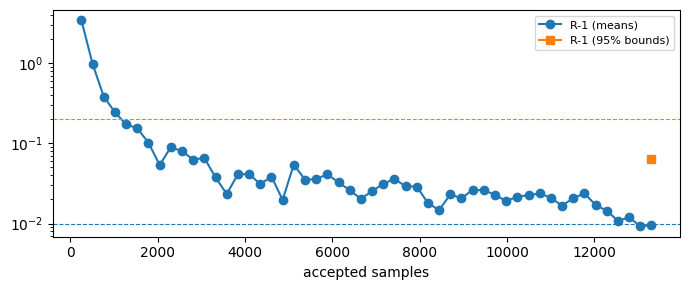

In [14]:
prog = np.atleast_1d(np.genfromtxt(CHAIN_ROOT + '.progress', names=True))
if prog.size == 0 or not np.isfinite(prog['N']).any():
    print('No convergence checkpoints written yet (the chain is still short).')
else:
    print('Cobaya progress (last 5 checkpoints):')
    print(f'{"N accepted":>12} {"acceptance":>11} {"R-1 (means)":>12} {"R-1 (95%)":>10}')
    for row in prog[-5:]:
        print(f'{int(row["N"]):12d} {row["acceptance_rate"]:11.3f} {row["Rminus1"]:12.4f} {row["Rminus1_cl"]:10.4f}')

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.semilogy(prog['N'], prog['Rminus1'], 'o-', label='R-1 (means)')
    ax.semilogy(prog['N'], prog['Rminus1_cl'], 's-', label='R-1 (95% bounds)')
    ax.axhline(0.01, color='C0', ls='--', lw=0.8); ax.axhline(0.2, color='C1', ls='--', lw=0.8)
    ax.set_xlabel('accepted samples'); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(IMG_DIR + f'/{TAG}_convergence.png', dpi=150); plt.show()

# Cell 11 : Posterior Summary

Includes 

1. the derived $\Omega_m$.
2. the **pivot** equation of state: $a_p = 1 + \mathrm{Cov}(w_0,w_a)/\mathrm{Var}(w_a)$,
$w_p = w_0 + w_a(1-a_p)$, 
3. $w_0$–$w_a$ contour.

In [15]:
print(f'=== {DATA_LABEL} — w0waCDM Posterior ===')
for p in PARAM_NAMES + ['omegam', 'rdrag']:
    print('  ' + gd.getInlineLatex(p, limit=1))

w0_s = gd.samples[:, gd.index['w']]
wa_s = gd.samples[:, gd.index['wa']]
wts  = gd.weights
cov_w = np.cov(np.vstack([w0_s, wa_s]), aweights=wts)
a_p   = 1.0 + cov_w[0, 1] / cov_w[1, 1]
wp_s  = w0_s + wa_s * (1.0 - a_p)
wp_mean = np.average(wp_s, weights=wts)
wp_std  = np.sqrt(np.average((wp_s - wp_mean)**2, weights=wts))
print(f'\nPivot: z_p = {1/a_p - 1:.3f},  w_p = {wp_mean:.3f} ± {wp_std:.3f}')

mu  = np.array([np.average(w0_s, weights=wts), np.average(wa_s, weights=wts)])
d   = mu - np.array([-1.0, 0.0])
c2  = float(d @ np.linalg.solve(cov_w, d))
sig = stats.norm.isf(stats.chi2.sf(c2, 2) / 2)
print(f'LCDM point from the w0-wa posterior: {sig:.2f} sigma (Gaussian approximation)')

=== WMAP9 + DESI DR2 + Pantheon+ — w0waCDM Posterior ===
  \Omega_b h^2 = 0.02255\pm 0.00043
  \Omega_c h^2 = 0.1153\pm 0.0024
  H_0 = 67.33\pm 0.70
  n_s = 0.972\pm 0.010
  \ln(10^{10}A_s) = 3.096\pm 0.029
  \tau = 0.087^{+0.012}_{-0.014}
  w_0 = -0.886\pm 0.059
  w_a = -0.25^{+0.28}_{-0.24}
  \Omega_m = 0.3056\pm 0.0063
  r_d = 148.15\pm 0.87

Pivot: z_p = 0.247,  w_p = -0.936 ± 0.028
LCDM point from the w0-wa posterior: 2.01 sigma (Gaussian approximation)


# Cell 12 : Trace Plot

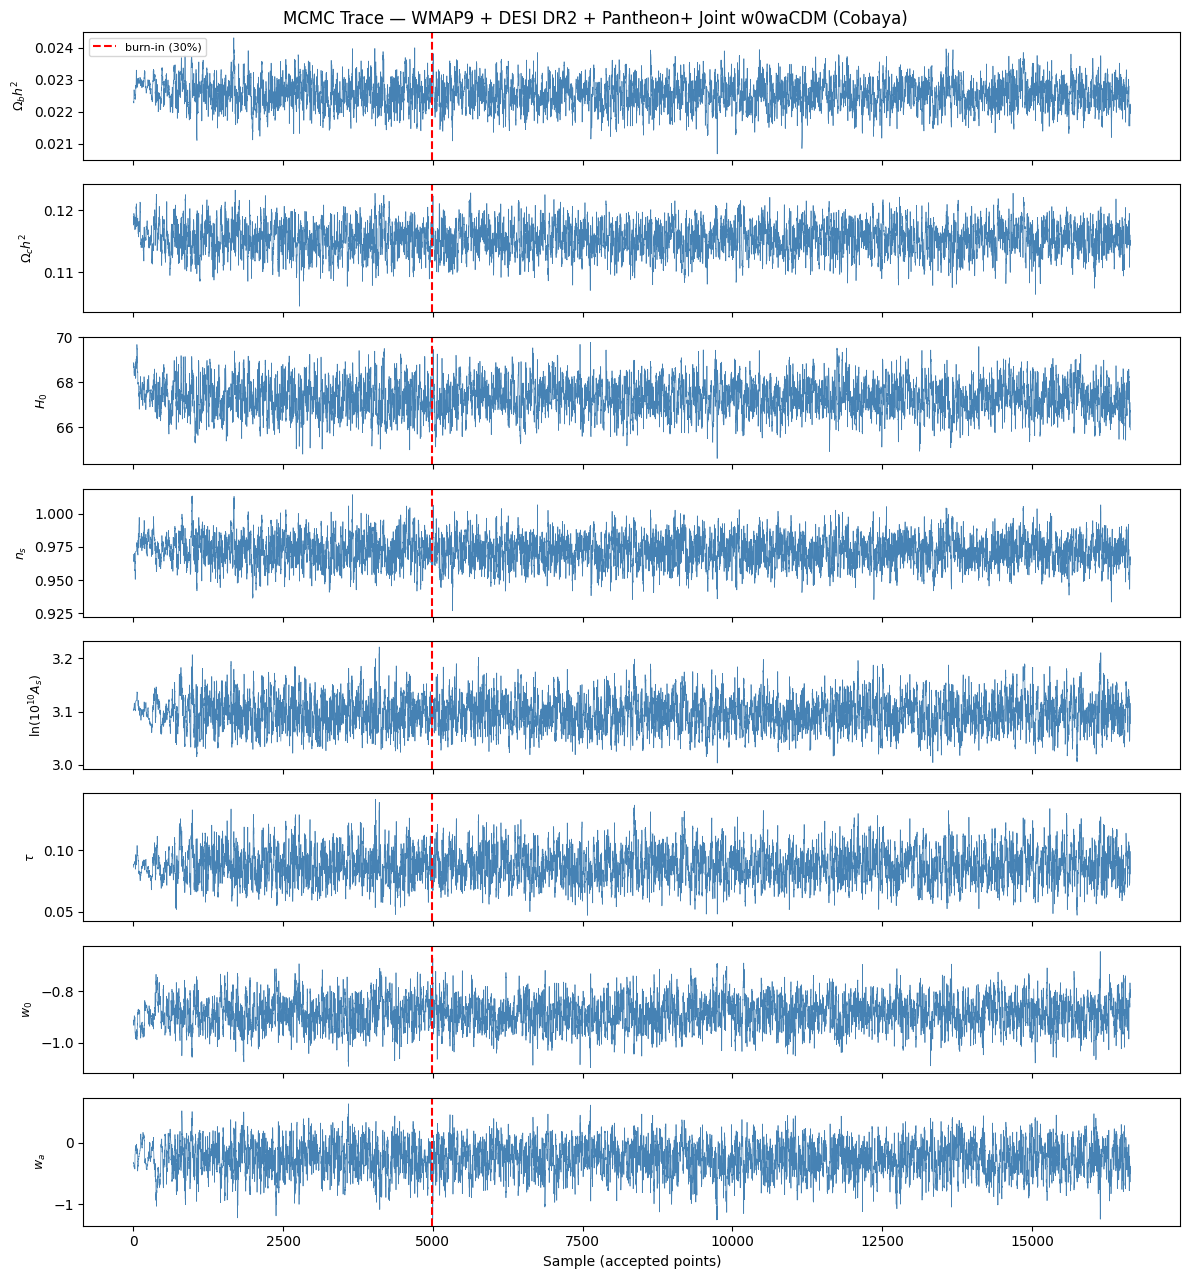

Saved: /Users/cherianpi/Desktop/Cosmology/analyses/wmap9_desi_dr2_pantheon_w0wa/figures/wmap9_dr2_pantheonplus_trace.png


In [16]:
with open(CHAIN_ROOT + '.1.txt') as fh:                 # Cobaya chain: weight, -logpost, params...
    cols = fh.readline().lstrip('#').split()
    raw  = np.loadtxt(fh)
burn = int(0.3 * len(raw))
fig, axes = plt.subplots(len(PARAM_NAMES), 1, figsize=(12, 13), sharex=True)
for ax, name, lbl in zip(axes, PARAM_NAMES, PARAM_LABELS):
    ax.plot(raw[:, cols.index(name)], lw=0.5, color='steelblue')
    ax.axvline(burn, color='red', ls='--', lw=1.5, label='burn-in (30%)')
    ax.set_ylabel(lbl, fontsize=9)
axes[0].legend(fontsize=8)
axes[-1].set_xlabel('Sample (accepted points)')
fig.suptitle(f'MCMC Trace — {DATA_LABEL} Joint w0waCDM (Cobaya)', fontsize=12)
plt.tight_layout()
fname = IMG_DIR + f'/{TAG}_trace.png'
plt.savefig(fname, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fname}')

# Cell 13 : Corner Plot

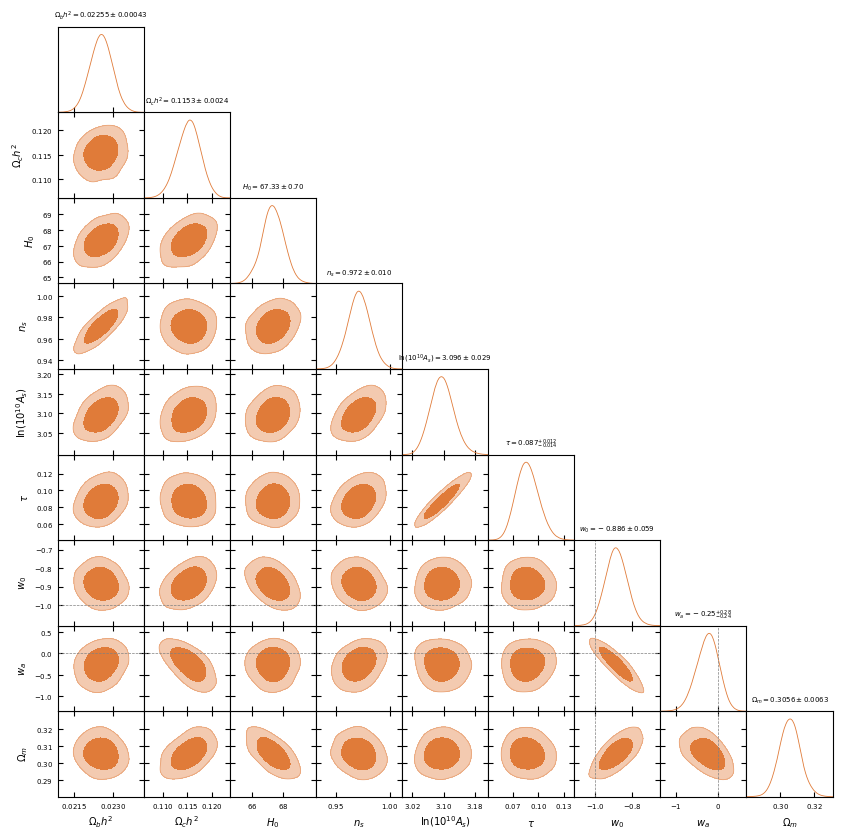

In [17]:
g = plots.get_subplot_plotter(width_inch=10)
g.settings.axes_fontsize = 9
g.settings.axes_labelsize = 12
g.settings.title_limit_fontsize = 9
g.triangle_plot([gd], PARAM_NAMES + ['omegam'], filled=True,
                contour_colors=['#E07B39'], title_limit=1,
                markers={'w': -1.0, 'wa': 0.0})            # LCDM values marked
g.export(IMG_DIR + f'/{TAG}_corner.pdf')
g.export(IMG_DIR + f'/{TAG}_corner.png')
plt.show()

# Cell 14 : The $w_0$–$w_a$ plane

68% and 95% contours with the ΛCDM point marked.\
Also, the grey region $w_0 + w_a > 0$ is excluded by the prior.


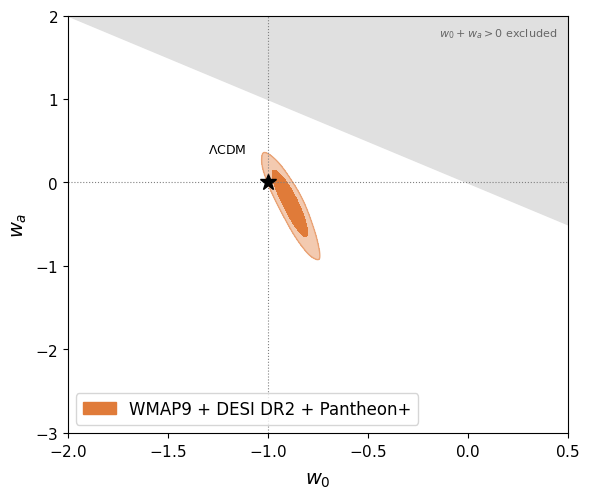

In [18]:
samples, colours = [gd], ['#E07B39']
gd.label = DATA_LABEL
other_tag = 'wmap9_dr2' if USE_SN else 'wmap9_dr2_pantheonplus'
other_root = CHAIN_DIR + f'/{other_tag}_w0wa'
if os.path.exists(other_root + '.1.txt'):
    gd_o = loadMCSamples(other_root, settings={'ignore_rows': 0.3})
    gd_o.label = 'WMAP9 + DESI DR2' + ('' if USE_SN else ' + Pantheon+')
    samples.insert(0, gd_o); colours.insert(0, '#4C72B0')

g = plots.get_single_plotter(width_inch=6, ratio=0.85)
g.plot_2d(samples, 'w', 'wa', filled=True, colors=colours, lims=[-2.0, 0.5, -3.0, 2.0])
ax = g.subplots[0, 0]
x = np.linspace(-2.0, 0.5, 50)
ax.fill_between(x, -x, 2.0, color='0.88', zorder=0)
ax.text(0.45, 1.75, r'$w_0+w_a>0$ excluded', ha='right', fontsize=8, color='0.4')
ax.axvline(-1, color='0.5', lw=0.8, ls=':'); ax.axhline(0, color='0.5', lw=0.8, ls=':')
ax.plot(-1, 0, marker='*', color='k', ms=12, zorder=10)
ax.annotate(r'$\Lambda$CDM', (-1, 0), xytext=(-1.3, 0.35), fontsize=9)
g.add_legend([s.label for s in samples], legend_loc='lower left')
g.export(IMG_DIR + f'/{TAG}_w0_wa.pdf')
g.export(IMG_DIR + f'/{TAG}_w0_wa.png')
plt.show()

# Cell 15 : Comparison with the WMAP9 posteriors

The existing WMAP9-alone and WMAP9 + DESI DR1 ΛCDM chains copied from `reference_chains/`, in the $H_0$–$\Omega_m$ plane and for the shared ΛCDM parameters.

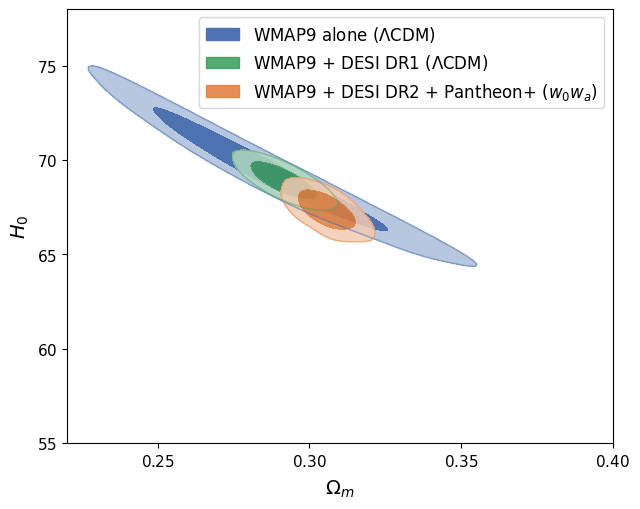

                  WMAP9 alone     WMAP9+DR1 (LCDM)      WMAP+DR2 (w0wa)
ombh2         0.0226 ± 0.0005      0.0225 ± 0.0004      0.0225 ± 0.0004
omch2         0.1142 ± 0.0045      0.1151 ± 0.0020      0.1153 ± 0.0024
H0           69.3946 ± 2.1541     68.9053 ± 0.6513     67.3341 ± 0.7004
ns            0.9739 ± 0.0130      0.9720 ± 0.0102      0.9716 ± 0.0103
logA          3.0954 ± 0.0307      3.0962 ± 0.0294      3.0961 ± 0.0295
tau           0.0887 ± 0.0142      0.0877 ± 0.0131      0.0873 ± 0.0133
omegam        0.2868 ± 0.0260      0.2914 ± 0.0071      0.3056 ± 0.0063


In [34]:
names_ref  = ['ombh2', 'omch2', 'H0', 'ns', 'logA', 'tau', 'omegam']
labels_ref = [LATEX[n] for n in names_ref[:-1]] + [r'\Omega_m']

def ref_samples(path, label):
    x  = np.load(path)
    Om = (x[:, 0] + x[:, 1] + 0.06 / 93.14) / (x[:, 2] / 100)**2
    return MCSamples(samples=np.column_stack([x, Om]), names=names_ref, labels=labels_ref, label=label,
                     settings={'smooth_scale_1D': 0.5, 'smooth_scale_2D': 0.5})

wmap_alone = ref_samples(REF_DIR + '/wmap9_lcdm_flat_samples_20260614_235110.npy', r'WMAP9 alone ($\Lambda$CDM)')
joint_dr1  = ref_samples(REF_DIR + '/wmap9_desi_joint_corrected_flat_20261024_212301.npy',
                         r'WMAP9 + DESI DR1 ($\Lambda$CDM)')
gd.label = DATA_LABEL + r' ($w_0w_a$)'

g = plots.get_single_plotter(width_inch=6.5, ratio=0.8)
g.plot_2d([wmap_alone, joint_dr1, gd], 'omegam', 'H0', filled=True,
          colors=['#4C72B0', '#3A9B5C', '#E07B39'], lims=[0.22, 0.40, 55, 78])
g.add_legend([wmap_alone.label, joint_dr1.label, gd.label], legend_loc='upper right')
g.export(IMG_DIR + f'/{TAG}_H0_Om_vs_wmap.png')
plt.show()

print(f'{"":8s} {"WMAP9 alone":>20s} {"WMAP9+DR1 (LCDM)":>20s} {"WMAP+DR2 (w0wa)":>20s}')
for p in ['ombh2', 'omch2', 'H0', 'ns', 'logA', 'tau', 'omegam']:
    vals = [s.mean(p) for s in (wmap_alone, joint_dr1, gd)]
    errs = [s.std(p)  for s in (wmap_alone, joint_dr1, gd)]
    print(f'{p:8s} ' + ' '.join(f'{v:11.4f} ± {e:6.4f}' for v, e in zip(vals, errs)))

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

# 1. Open the chain file (edit the path if needed)
fname = 'chains/wmap9_dr2_pantheonplus_w0wa.1.txt'
with open(fname) as f:
    cols = f.readline().lstrip('#').split()      # column names from the header
data = np.loadtxt(fname)
print('Data Loaded Successfully')


Data Loaded Successfully


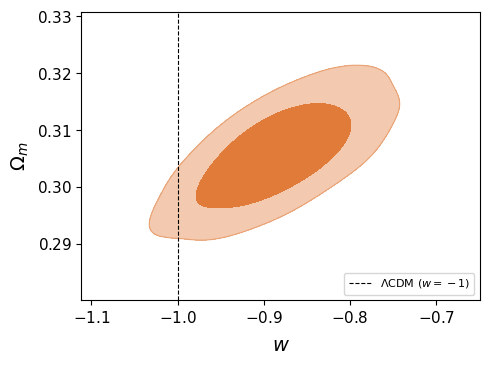

In [33]:
# 2. Drop the first 30% as burn-in
data = data[int(0.3 * len(data)):]
weights = data[:, cols.index('weight')]
w0 = data[:, cols.index('w')]
om = data[:, cols.index('omegam')]

# 3. Make GetDist samples
s = MCSamples(samples=np.column_stack([om, w0]), weights=weights,
              names=['omegam', 'w'], labels=[r'\Omega_m', r'w'],
              label='WMAP9 + DESI DR2 + Pantheon+')

# 4. Plot the 68% and 95% contours
g = plots.get_single_plotter(width_inch=5)
g.plot_2d(s, 'w','omegam',  filled=True, colors=['#E07B39'])
ax = g.subplots[0, 0]
ax.axvline(-1, color='k', ls='--', lw=0.8, label=r'$\Lambda$CDM ($w=-1$)')
ax.legend(loc='lower right', fontsize=8)
g.export('figures/omegam_w0.png')
plt.show()

# Cell 16 : Final Summary

In [20]:
print('=' * 65)
print(f'  {DATA_LABEL} — Joint w0waCDM Final Summary (Cobaya)')
print('=' * 65)
print(f'  Likelihoods : {", ".join(model.likelihood)}')
print(f'  Samples     : {gd.numrows} (after 30% burn-in)')
print(f'  Final R-1   : {prog[-1]["Rminus1"]:.4f}' if prog.size and np.isfinite(prog['N']).any() else '  Final R-1   : n/a')
print()
for p in PARAM_NAMES + ['omegam']:
    print(f'  {p:<8} {gd.mean(p):10.5f} ± {gd.std(p):8.5f}')
print(f'  {"w_p":<8} {wp_mean:10.5f} ± {wp_std:8.5f}   (z_p = {1/a_p - 1:.3f})')
print()
print(f'  chi2_min LCDM = {float(best["lcdm"]["chi2"]):.2f}   chi2_min w0wa = {float(best["w0wa"]["chi2"]):.2f}')
print(f'  Delta chi2    = {dchi2:.2f}  ->  {sigma:.2f} sigma preference for w0wa (2 extra parameters)')
print('=' * 65)

  WMAP9 + DESI DR2 + Pantheon+ — Joint w0waCDM Final Summary (Cobaya)
  Likelihoods : wmap9, bao.desi_dr2.desi_bao_all, sn.pantheonplus
  Samples     : 11648 (after 30% burn-in)
  Final R-1   : 0.0096

  ombh2       0.02255 ±  0.00043
  omch2       0.11534 ±  0.00237
  H0         67.33410 ±  0.70039
  ns          0.97159 ±  0.01032
  logA        3.09615 ±  0.02948
  tau         0.08734 ±  0.01331
  w          -0.88576 ±  0.05852
  wa         -0.25446 ±  0.25972
  omegam      0.30561 ±  0.00627
  w_p        -0.93624 ±  0.02776   (z_p = 0.247)

  chi2_min LCDM = 8975.45   chi2_min w0wa = 8969.52
  Delta chi2    = 5.93  ->  1.95 sigma preference for w0wa (2 extra parameters)
